# Trabalho #2 — Regressão de Altura e Peso de Bovinos com CNNs
**Aprendizado de Máquina Profundo (UFSM00993) — Prof. Dr. Thiago L. T. da Silveira**

**Grupo:** _(preencher nomes)_

Objetivo: a partir de uma imagem de um bovino, estimar simultaneamente

$$\hat{y} = \begin{bmatrix}\widehat{\text{altura}} & \widehat{\text{peso}}\end{bmatrix}$$

com uma CNN de no máximo 5.000.000 de parâmetros, implementada em TensorFlow/Keras.

**Roteiro do notebook**
1. Download e leitura dos dados
2. Pré-processamento e divisão treino/validação
3. Arquiteturas (CNN do zero com blocos residuais e CNN com backbone pré-treinado)
4. Função de perda e otimizador
5. Treinamento e curvas de perda
6. Métricas (MAE e RMSE por variável)
7. Regularização, aumento de dados, busca de hiperparâmetros, salvamento e recarga do melhor modelo
8. Análise dos resultados
9. Predição no conjunto de teste e geração do `.csv`

> **Ambiente:** use *Ambiente de execução → Alterar o tipo de ambiente de execução → GPU (T4)*.

## 1. Download e leitura dos dados

In [1]:
!wget -q -nc https://raw.githubusercontent.com/tltsilveira/ufsm00993/main/dataset_8.zip
!unzip -qo dataset_8.zip
!pip install -q keras-tuner

In [2]:
import os, csv, zipfile, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import skimage.io as io
import tensorflow as tf
import keras
from keras import layers, models, regularizers, callbacks

SEED = 42
keras.utils.set_random_seed(SEED)
print('TensorFlow', tf.__version__, '| Keras', keras.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TAM = 256  # todas as imagens do dataset são 256x256x3

TensorFlow 2.21.0 | Keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


O arquivo `annotations.csv` **não tem cabeçalho**: cada linha é `id,altura,peso` (ex.: `001,123,279`) e a imagem correspondente é `images/<id>.jpg`.
O identificador é mantido como *string* para preservar os zeros à esquerda. A pasta `images` contém uma imagem a mais (`334.jpg`) sem anotação, por isso a lista de amostras é montada a partir do CSV.

In [3]:
def ler_imagem(caminho):
    img = io.imread(caminho)
    if img.ndim == 2:                      # tons de cinza -> RGB
        img = np.stack([img] * 3, axis=-1)
    img = img[..., :3]                     # descarta canal alfa, se houver
    if img.shape[:2] != (TAM, TAM):
        from skimage.transform import resize
        img = (resize(img, (TAM, TAM), anti_aliasing=True) * 255).astype('uint8')
    return img

with open('annotations.csv', newline='') as f:
    linhas = [l for l in csv.reader(f) if l]

ids = [l[0] for l in linhas]
Y = np.array([[float(l[1]), float(l[2])] for l in linhas], dtype='float32')
X = np.stack([ler_imagem(f'images/{i}.jpg') for i in ids])

print('Imagens:', X.shape, X.dtype, '| Anotações:', Y.shape)
print(f'Altura: min={Y[:,0].min():.0f}  max={Y[:,0].max():.0f}  média={Y[:,0].mean():.1f}  dp={Y[:,0].std():.1f} cm')
print(f'Peso:   min={Y[:,1].min():.0f}  max={Y[:,1].max():.0f}  média={Y[:,1].mean():.1f}  dp={Y[:,1].std():.1f} kg')
print('Correlação altura x peso:', np.corrcoef(Y[:,0], Y[:,1])[0,1].round(3))

Imagens: (513, 256, 256, 3) uint8 | Anotações: (513, 2)
Altura: min=97  max=148  média=118.5  dp=8.2 cm
Peso:   min=150  max=816  média=256.0  dp=74.2 kg
Correlação altura x peso: 0.774


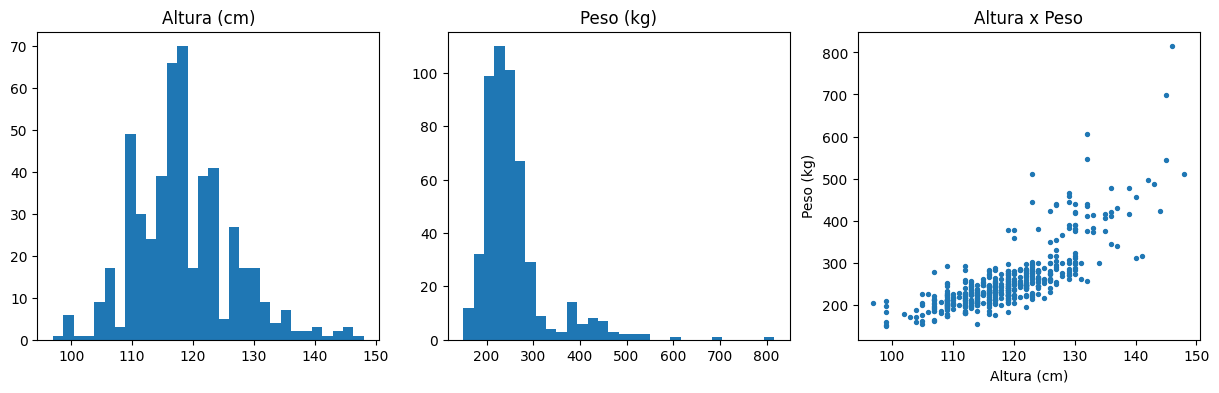

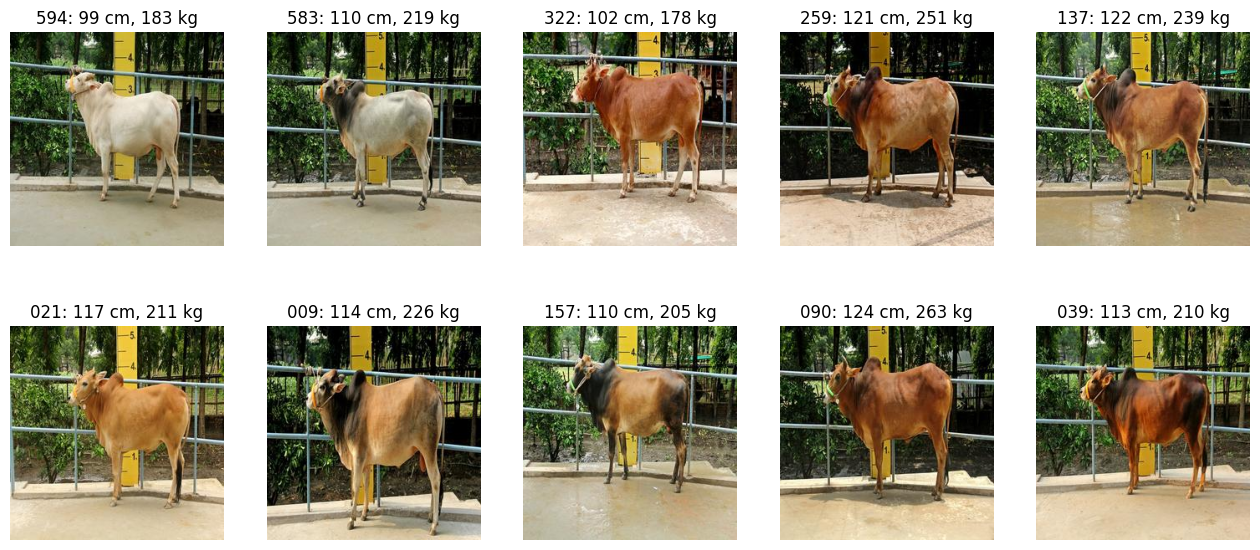

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(Y[:,0], bins=30); ax[0].set_title('Altura (cm)')
ax[1].hist(Y[:,1], bins=30); ax[1].set_title('Peso (kg)')
ax[2].scatter(Y[:,0], Y[:,1], s=8); ax[2].set_xlabel('Altura (cm)'); ax[2].set_ylabel('Peso (kg)')
ax[2].set_title('Altura x Peso')
plt.show()

fig, ax = plt.subplots(2, 5, figsize=(16, 7))
for a, k in zip(ax.ravel(), np.random.default_rng(0).choice(len(X), 10, replace=False)):
    a.imshow(X[k]); a.set_title(f'{ids[k]}: {Y[k,0]:.0f} cm, {Y[k,1]:.0f} kg'); a.axis('off')
plt.show()

**Observações:** as fotos são tiradas de perfil, em um ambiente padronizado e com uma régua graduada ao fundo, que serve de referência de escala. O peso tem distribuição assimétrica, com poucos animais muito pesados (outliers acima de 500 kg). Altura e peso são fortemente correlacionados, o que motiva uma representação convolucional compartilhada para as duas tarefas.

## 2. Pré-processamento e divisão dos dados

- **Pixels:** normalizados para $[0,1]$ (divisão por 255).
- **Divisão:** as 50 primeiras linhas de `annotations.csv` formam a validação e as demais, o treino.
- **Alvos:** altura (dp ≈ 8 cm) e peso (dp ≈ 74 kg) têm escalas muito diferentes. Sem normalização, a perda seria dominada pelo peso. Por isso os alvos são padronizados (*z-score*) **com as estatísticas do treino**, e as previsões são desnormalizadas antes de calcular as métricas.

In [5]:
X = X.astype('float32') / 255.0

N_VAL = 50
Xva, Yva, ids_va = X[:N_VAL], Y[:N_VAL], ids[:N_VAL]
Xtr, Ytr, ids_tr = X[N_VAL:], Y[N_VAL:], ids[N_VAL:]

MU, SD = Ytr.mean(axis=0), Ytr.std(axis=0)
Ytr_n, Yva_n = (Ytr - MU) / SD, (Yva - MU) / SD
print('Treino:', Xtr.shape, '| Validação:', Xva.shape)
print('MU =', MU, '| SD =', SD)

def alvos(Yn, duas_cabecas):
    # duas cabeças -> lista [altura, peso]; uma cabeça -> matriz (N, 2)
    return [Yn[:, 0:1], Yn[:, 1:2]] if duas_cabecas else Yn

Treino: (463, 256, 256, 3) | Validação: (50, 256, 256, 3)
MU = [118.62635 258.37796] | SD = [ 8.395248 76.92019 ]


## 3. Arquiteturas

**Aumento de dados** (ativo apenas no treino): espelhamento horizontal, pequenas translações e rotações, e variações de brilho e contraste. Zoom e recortes agressivos foram evitados de propósito: a escala aparente do animal em relação à régua é justamente a informação que o modelo precisa para estimar tamanho e peso.

Foram implementadas duas famílias de modelos:

**(a) CNN do zero com blocos residuais (Aula 18).** Uma camada inicial convolucional seguida de blocos `Conv–BN–ReLU–Conv–BN + atalho` com 32, 64, 128 e 256 filtros, *max-pooling* entre os blocos e *Global Average Pooling* ao final (Aula 20).

**(b) Transfer learning (bônus 1)** com **EfficientNetB0** pré-treinada no ImageNet (≈4,05M parâmetros), usando *depthwise separable convolutions* e blocos residuais invertidos (bônus 2). As camadas iniciais ficam congeladas e o modelo recebe novas cabeças de regressão. O treino é feito em duas fases: (1) backbone congelado; (2) *fine-tuning* das camadas finais com taxa de aprendizado baixa. A EfficientNet espera pixels em $[0,255]$, por isso uma camada `Rescaling(255)` desfaz a normalização dentro do modelo.

**Saídas (bônus 3):** a opção `duas_cabecas=True` usa a representação compartilhada seguida de duas cabeças independentes (`altura` e `peso`); a opção `duas_cabecas=False` usa uma única camada `Dense(2)`. As saídas são lineares, sem ativação, como é usual em regressão.

In [6]:
def bloco_aumento():
    return keras.Sequential([
        layers.RandomFlip('horizontal'),
        layers.RandomTranslation(0.05, 0.05, fill_mode='reflect'),
        layers.RandomRotation(0.02, fill_mode='reflect'),
        layers.RandomBrightness(0.15, value_range=(0.0, 1.0)),
        layers.RandomContrast(0.15),
    ], name='aumento')

def cabecas(z, duas_cabecas, unidades=128, dropout=0.3, l2=1e-4):
    reg = regularizers.l2(l2)
    if duas_cabecas:
        a = layers.Dense(unidades, activation='relu', kernel_regularizer=reg)(z)
        a = layers.Dropout(dropout)(a)
        a = layers.Dense(1, name='altura')(a)
        p = layers.Dense(unidades, activation='relu', kernel_regularizer=reg)(z)
        p = layers.Dropout(dropout)(p)
        p = layers.Dense(1, name='peso')(p)
        return [a, p]
    h = layers.Dense(unidades, activation='relu', kernel_regularizer=reg)(z)
    h = layers.Dropout(dropout)(h)
    return layers.Dense(2, name='altura_peso')(h)

def bloco_residual(x, filtros, l2=1e-4):
    reg = regularizers.l2(l2)
    atalho = x
    if x.shape[-1] != filtros:  # conv 1x1 para igualar o número de canais
        atalho = layers.Conv2D(filtros, 1, padding='same', kernel_regularizer=reg)(x)
    x = layers.Conv2D(filtros, 3, padding='same', use_bias=False, kernel_regularizer=reg)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filtros, 3, padding='same', use_bias=False, kernel_regularizer=reg)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Add()([x, atalho])
    return layers.ReLU()(x)

def cnn_do_zero(duas_cabecas=True, dropout=0.3):
    ent = keras.Input((TAM, TAM, 3))
    x = bloco_aumento()(ent)
    x = layers.Conv2D(32, 5, strides=2, padding='same', use_bias=False)(x)  # 128x128
    x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    for f in [32, 64, 128, 256]:
        x = bloco_residual(x, f)
        x = layers.MaxPooling2D(2)(x)                                       # 64 -> 32 -> 16 -> 8
    z = layers.GlobalAveragePooling2D()(x)
    z = layers.Dropout(dropout)(z)
    return keras.Model(ent, cabecas(z, duas_cabecas, dropout=dropout), name='cnn_residual_do_zero')

def cnn_transfer(duas_cabecas=True, unidades=128, dropout=0.3, l2=1e-4):
    base = keras.applications.EfficientNetB0(include_top=False, weights='imagenet',
                                             input_shape=(TAM, TAM, 3))
    base.trainable = False
    ent = keras.Input((TAM, TAM, 3))
    x = bloco_aumento()(ent)
    x = layers.Rescaling(255.0)(x)        # EfficientNet espera pixels em [0, 255]
    x = base(x, training=False)           # mantém BatchNorm em modo inferência
    z = layers.GlobalAveragePooling2D()(x)
    z = layers.Dropout(dropout)(z)
    nome = 'efficientnetb0_' + ('2cabecas' if duas_cabecas else '1cabeca')
    return keras.Model(ent, cabecas(z, duas_cabecas, unidades, dropout, l2), name=nome), base

LIMITE = 5_000_000
for m in [cnn_do_zero(), cnn_transfer()[0], cnn_transfer(duas_cabecas=False)[0]]:
    n = m.count_params()
    print(f'{m.name:28s} {n:>10,d} parâmetros  {"OK" if n <= LIMITE else "ACIMA DO LIMITE!"}')

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
cnn_residual_do_zero          1,295,522 parâmetros  OK
efficientnetb0_2cabecas       4,377,765 parâmetros  OK
efficientnetb0_1cabeca        4,213,797 parâmetros  OK


## 4. Função de perda, otimizador e funções auxiliares

- **Perda:** *Huber* (Smooth L1) sobre os alvos padronizados. Ela se comporta como o MSE para erros pequenos e como o MAE para erros grandes, o que reduz a influência dos poucos animais muito pesados (outliers) sem abrir mão de gradientes suaves perto do mínimo. O MSE e o MAE são avaliados na busca de hiperparâmetros.
- **Otimizador:** Adam (Aula 8), com `ReduceLROnPlateau` (*learning-rate scheduler*) e `EarlyStopping` com restauração dos melhores pesos (regularização heurística, Aula 12).
- **Métricas:** MAE e RMSE calculados **em unidades reais** (cm e kg), após desnormalizar as previsões.

In [7]:
def compilar(model, lr=1e-3, perda='huber'):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss=perda)

def treinar(model, duas_cabecas, epocas, paciencia=15, batch=16):
    cbs = [callbacks.EarlyStopping(monitor='val_loss', patience=paciencia, restore_best_weights=True),
           callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=max(3, paciencia // 3), min_lr=1e-7)]
    return model.fit(Xtr, alvos(Ytr_n, duas_cabecas),
                     validation_data=(Xva, alvos(Yva_n, duas_cabecas)),
                     epochs=epocas, batch_size=batch, callbacks=cbs, verbose=2)

def prever(model, Xs, batch=32):
    p = model.predict(Xs, batch_size=batch, verbose=0)
    if isinstance(p, (list, tuple)):
        p = np.concatenate(p, axis=1)
    return p * SD + MU

def metricas(Yreal, Ypred):
    e = Ypred - Yreal
    mae, rmse = np.abs(e).mean(0), np.sqrt((e ** 2).mean(0))
    mape = (np.abs(e) / Yreal).mean(0) * 100
    return {'MAE altura (cm)': mae[0], 'RMSE altura (cm)': rmse[0], 'MAPE altura (%)': mape[0],
            'MAE peso (kg)': mae[1], 'RMSE peso (kg)': rmse[1], 'MAPE peso (%)': mape[1]}

def mostrar(nome, m):
    print(f'{nome}:  altura MAE={m["MAE altura (cm)"]:.2f} cm  RMSE={m["RMSE altura (cm)"]:.2f} cm  |  '
          f'peso MAE={m["MAE peso (kg)"]:.2f} kg  RMSE={m["RMSE peso (kg)"]:.2f} kg')

def curvas(historicos, titulo):
    loss, val = [], []
    for h in historicos:
        loss += h.history['loss']; val += h.history['val_loss']
    plt.figure(figsize=(8, 4))
    plt.plot(loss, label='treino'); plt.plot(val, label='validação')
    fim = 0
    for h in historicos[:-1]:
        fim += len(h.history['loss']); plt.axvline(fim - 0.5, ls='--', c='gray')
    plt.yscale('log'); plt.xlabel('época'); plt.ylabel('perda (Huber, alvos padronizados)')
    plt.title(titulo); plt.legend(); plt.grid(alpha=.3); plt.show()

resultados, modelos = {}, {}

# Referência: prever sempre a média do treino (qualquer modelo útil deve superar isso)
resultados['Baseline (média do treino)'] = metricas(Yva, np.tile(MU, (len(Yva), 1)))
mostrar('Baseline (média)', resultados['Baseline (média do treino)'])

Baseline (média):  altura MAE=5.06 cm  RMSE=6.28 cm  |  peso MAE=36.10 kg  RMSE=42.40 kg


## 5. Treinamento

### Experimento A — CNN residual treinada do zero (bônus 2)

Epoch 1/150
29/29 - 20s - 705ms/step - altura_loss: 0.8101 - loss: 1.6341 - peso_loss: 0.6762 - val_altura_loss: 0.4183 - val_loss: 0.8694 - val_peso_loss: 0.3915 - learning_rate: 0.0010
Epoch 2/150
29/29 - 3s - 89ms/step - altura_loss: 0.4260 - loss: 0.9518 - peso_loss: 0.3771 - val_altura_loss: 0.5091 - val_loss: 0.7785 - val_peso_loss: 0.2184 - learning_rate: 0.0010
Epoch 3/150
29/29 - 2s - 85ms/step - altura_loss: 0.3507 - loss: 0.7799 - peso_loss: 0.2811 - val_altura_loss: 0.3810 - val_loss: 0.6269 - val_peso_loss: 0.2130 - learning_rate: 0.0010
Epoch 4/150
29/29 - 2s - 81ms/step - altura_loss: 0.2767 - loss: 0.6751 - peso_loss: 0.2510 - val_altura_loss: 0.4705 - val_loss: 0.8120 - val_peso_loss: 0.3529 - learning_rate: 0.0010
Epoch 5/150
29/29 - 2s - 81ms/step - altura_loss: 0.2441 - loss: 0.6201 - peso_loss: 0.2290 - val_altura_loss: 0.4716 - val_loss: 0.7475 - val_peso_loss: 0.1276 - learning_rate: 0.0010
Epoch 6/150
29/29 - 2s - 83ms/step - altura_loss: 0.2444 - loss: 0.5771 -

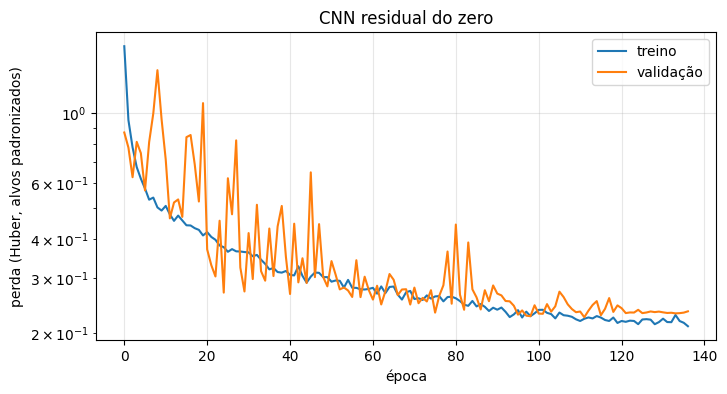

A:  altura MAE=2.52 cm  RMSE=3.10 cm  |  peso MAE=18.53 kg  RMSE=22.48 kg


In [8]:
EPOCAS_ZERO = 150
keras.utils.set_random_seed(SEED)
m_zero = cnn_do_zero(duas_cabecas=True)
compilar(m_zero, lr=1e-3)
h_zero = treinar(m_zero, True, EPOCAS_ZERO, paciencia=25)
curvas([h_zero], 'CNN residual do zero')
resultados['A: CNN residual do zero (2 cabeças)'] = metricas(Yva, prever(m_zero, Xva))
modelos['A: CNN residual do zero (2 cabeças)'] = m_zero
mostrar('A', resultados['A: CNN residual do zero (2 cabeças)'])

### Busca sistemática de hiperparâmetros com KerasTuner (bônus 4)

A busca é feita com o backbone **congelado**, o que a torna barata. São explorados a taxa de aprendizado, o dropout, o número de unidades das cabeças, a regularização L2 e a função de perda (Huber, MSE ou MAE).
Como cada perda tem uma escala diferente, o critério de seleção é o **MAE de validação em alvos padronizados** (`val_mae_total`), uma métrica comum a todas as configurações. Os melhores hiperparâmetros são usados no Experimento B.

In [9]:
RODAR_TUNER = True
TUNER_TENTATIVAS, TUNER_EPOCAS = 10, 25

class MAETotal(keras.callbacks.Callback):
    # registra a soma dos MAEs padronizados de validação (altura + peso) em logs['val_mae_total']
    def on_epoch_end(self, epoch, logs=None):
        p = self.model.predict(Xva, verbose=0)
        p = np.concatenate(p, axis=1) if isinstance(p, (list, tuple)) else p
        logs['val_mae_total'] = float(np.abs(p - Yva_n).mean(0).sum())

HP_PADRAO = {'lr': 1e-3, 'dropout': 0.3, 'unidades': 128, 'l2': 1e-4, 'perda': 'huber'}
melhores_hp = dict(HP_PADRAO)

if RODAR_TUNER:
    import keras_tuner as kt

    def construir(hp):
        m, _ = cnn_transfer(True,
                            unidades=hp.Choice('unidades', [64, 128, 256]),
                            dropout=hp.Float('dropout', 0.1, 0.5, step=0.1),
                            l2=hp.Choice('l2', [0.0, 1e-4, 1e-3]))
        compilar(m, lr=hp.Choice('lr', [3e-4, 1e-3, 3e-3]),
                 perda=hp.Choice('perda', ['huber', 'mse', 'mae']))
        return m

    tuner = kt.RandomSearch(construir, objective=kt.Objective('val_mae_total', 'min'),
                            max_trials=TUNER_TENTATIVAS, seed=SEED, overwrite=True,
                            directory='kt', project_name='bovinos')
    tuner.search(Xtr, alvos(Ytr_n, True), validation_data=(Xva, alvos(Yva_n, True)),
                 epochs=TUNER_EPOCAS, batch_size=16, verbose=1,
                 callbacks=[MAETotal(), callbacks.EarlyStopping(monitor='val_mae_total', mode='min',
                                                                patience=8, restore_best_weights=True)])
    tuner.results_summary(5)
    melhores_hp = tuner.get_best_hyperparameters(1)[0].values
print('Hiperparâmetros usados:', melhores_hp)

Trial 10 Complete [00h 01m 23s]
val_mae_total: 0.8573276996612549

Best val_mae_total So Far: 0.6983897089958191
Total elapsed time: 00h 12m 08s
Results summary
Results in kt/bovinos
Showing 5 best trials
Objective(name="val_mae_total", direction="min")

Trial 01 summary
Hyperparameters:
unidades: 128
dropout: 0.30000000000000004
l2: 0.0
lr: 0.001
perda: huber
Score: 0.6983897089958191

Trial 06 summary
Hyperparameters:
unidades: 64
dropout: 0.2
l2: 0.001
lr: 0.001
perda: mse
Score: 0.7124515175819397

Trial 00 summary
Hyperparameters:
unidades: 128
dropout: 0.1
l2: 0.0001
lr: 0.0003
perda: mae
Score: 0.7208112478256226

Trial 05 summary
Hyperparameters:
unidades: 64
dropout: 0.4
l2: 0.001
lr: 0.003
perda: huber
Score: 0.7344911098480225

Trial 04 summary
Hyperparameters:
unidades: 256
dropout: 0.30000000000000004
l2: 0.0001
lr: 0.001
perda: huber
Score: 0.7865849733352661
Hiperparâmetros usados: {'unidades': 128, 'dropout': 0.30000000000000004, 'l2': 0.0, 'lr': 0.001, 'perda': 'huber'

### Experimento B — EfficientNetB0 pré-treinada + duas cabeças (transfer learning + fine-tuning)

Epoch 1/60
29/29 - 16s - 558ms/step - altura_loss: 0.4169 - loss: 0.7551 - peso_loss: 0.3377 - val_altura_loss: 0.2055 - val_loss: 0.3194 - val_peso_loss: 0.1106 - learning_rate: 0.0010
Epoch 2/60
29/29 - 2s - 63ms/step - altura_loss: 0.2959 - loss: 0.5397 - peso_loss: 0.2439 - val_altura_loss: 0.1985 - val_loss: 0.4186 - val_peso_loss: 0.1755 - learning_rate: 0.0010
Epoch 3/60
29/29 - 2s - 67ms/step - altura_loss: 0.2653 - loss: 0.4534 - peso_loss: 0.1882 - val_altura_loss: 0.1620 - val_loss: 0.3046 - val_peso_loss: 0.1188 - learning_rate: 0.0010
Epoch 4/60
29/29 - 2s - 67ms/step - altura_loss: 0.2518 - loss: 0.4162 - peso_loss: 0.1642 - val_altura_loss: 0.1580 - val_loss: 0.2403 - val_peso_loss: 0.0763 - learning_rate: 0.0010
Epoch 5/60
29/29 - 2s - 62ms/step - altura_loss: 0.2343 - loss: 0.3872 - peso_loss: 0.1529 - val_altura_loss: 0.2151 - val_loss: 0.3037 - val_peso_loss: 0.0815 - learning_rate: 0.0010
Epoch 6/60
29/29 - 2s - 63ms/step - altura_loss: 0.2121 - loss: 0.3558 - peso_

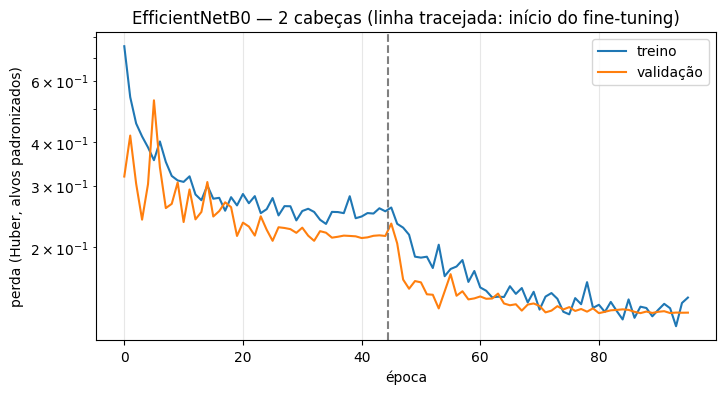

B:  altura MAE=2.62 cm  RMSE=3.35 cm  |  peso MAE=20.20 kg  RMSE=24.42 kg


In [10]:
EPOCAS_FASE1, EPOCAS_FASE2 = 60, 60
CAMADAS_FT = 60   # número de camadas finais da EfficientNet descongeladas na fase 2

def rodar_transfer(duas_cabecas, hp):
    keras.utils.set_random_seed(SEED)
    m, base = cnn_transfer(duas_cabecas, hp['unidades'], hp['dropout'], hp['l2'])
    # Fase 1: backbone congelado, treinam apenas as cabeças
    compilar(m, lr=hp['lr'], perda=hp['perda'])
    h1 = treinar(m, duas_cabecas, EPOCAS_FASE1, paciencia=12)
    # Fase 2: fine-tuning das últimas camadas (BatchNorm permanece congelada)
    base.trainable = True
    for camada in base.layers[:-CAMADAS_FT]:
        camada.trainable = False
    for camada in base.layers:
        if isinstance(camada, layers.BatchNormalization):
            camada.trainable = False
    compilar(m, lr=hp['lr'] / 30, perda=hp['perda'])  # lr ~30x menor no fine-tuning
    h2 = treinar(m, duas_cabecas, EPOCAS_FASE2, paciencia=15)
    return m, [h1, h2]

m_tl2, h_tl2 = rodar_transfer(True, melhores_hp)
curvas(h_tl2, 'EfficientNetB0 — 2 cabeças (linha tracejada: início do fine-tuning)')
resultados['B: EfficientNetB0 + 2 cabeças'] = metricas(Yva, prever(m_tl2, Xva))
modelos['B: EfficientNetB0 + 2 cabeças'] = m_tl2
mostrar('B', resultados['B: EfficientNetB0 + 2 cabeças'])

### Experimento C — EfficientNetB0 pré-treinada + uma única camada de saída (bônus 3)

Epoch 1/60
29/29 - 14s - 496ms/step - loss: 0.3677 - val_loss: 0.1892 - learning_rate: 0.0010
Epoch 2/60
29/29 - 2s - 76ms/step - loss: 0.2598 - val_loss: 0.1865 - learning_rate: 0.0010
Epoch 3/60
29/29 - 2s - 68ms/step - loss: 0.2370 - val_loss: 0.1340 - learning_rate: 0.0010
Epoch 4/60
29/29 - 2s - 66ms/step - loss: 0.2124 - val_loss: 0.1332 - learning_rate: 0.0010
Epoch 5/60
29/29 - 2s - 61ms/step - loss: 0.2122 - val_loss: 0.1479 - learning_rate: 0.0010
Epoch 6/60
29/29 - 2s - 62ms/step - loss: 0.1888 - val_loss: 0.2937 - learning_rate: 0.0010
Epoch 7/60
29/29 - 2s - 61ms/step - loss: 0.2086 - val_loss: 0.1734 - learning_rate: 0.0010
Epoch 8/60
29/29 - 2s - 68ms/step - loss: 0.1776 - val_loss: 0.1078 - learning_rate: 0.0010
Epoch 9/60
29/29 - 2s - 68ms/step - loss: 0.1637 - val_loss: 0.1833 - learning_rate: 0.0010
Epoch 10/60
29/29 - 2s - 61ms/step - loss: 0.1695 - val_loss: 0.1842 - learning_rate: 0.0010
Epoch 11/60
29/29 - 2s - 61ms/step - loss: 0.1615 - val_loss: 0.1433 - learni

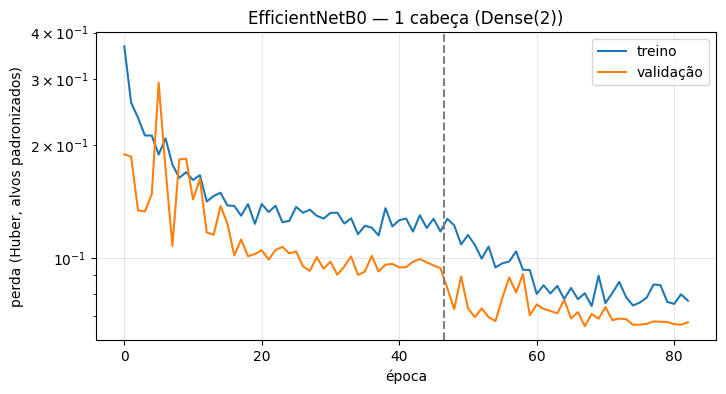

C:  altura MAE=2.62 cm  RMSE=3.35 cm  |  peso MAE=20.51 kg  RMSE=24.79 kg


In [11]:
m_tl1, h_tl1 = rodar_transfer(False, melhores_hp)
curvas(h_tl1, 'EfficientNetB0 — 1 cabeça (Dense(2))')
resultados['C: EfficientNetB0 + 1 cabeça'] = metricas(Yva, prever(m_tl1, Xva))
modelos['C: EfficientNetB0 + 1 cabeça'] = m_tl1
mostrar('C', resultados['C: EfficientNetB0 + 1 cabeça'])

### Comparação dos experimentos (conjunto de validação)

In [12]:
import pandas as pd
tabela = pd.DataFrame(resultados).T
tabela['parâmetros'] = [modelos[k].count_params() if k in modelos else 0 for k in tabela.index]
display(tabela.round(2))

,MAE altura (cm),RMSE altura (cm),MAPE altura (%),MAE peso (kg),RMSE peso (kg),MAPE peso (%),parâmetros
Baseline (média do treino),5.06,6.28,4.32,36.099998,42.400002,16.50,0
A: CNN residual do zero (2 cabeças),2.52,3.10,2.12,18.530001,22.480000,8.04,1295522
B: EfficientNetB0 + 2 cabeças,2.62,3.35,2.21,20.200001,24.420000,8.87,4377765
C: EfficientNetB0 + 1 cabeça,2.62,3.35,2.20,20.510000,24.790001,8.95,4213797


## 6–7. Melhor modelo: salvamento e recarga

O melhor modelo é escolhido pela soma dos MAEs **relativos ao desvio padrão** de cada variável, para que altura e peso tenham o mesmo peso na decisão.
Em seguida, ele é salvo em `.keras`, recarregado, e as previsões dos dois são comparadas.

In [13]:
def criterio(m):
    return m['MAE altura (cm)'] / SD[0] + m['MAE peso (kg)'] / SD[1]

nome_melhor = min(modelos, key=lambda k: criterio(resultados[k]))
melhor = modelos[nome_melhor]
print('Melhor modelo:', nome_melhor)

melhor.save('melhor_modelo.keras')
carregado = keras.models.load_model('melhor_modelo.keras')

p_orig, p_carr = prever(melhor, Xva), prever(carregado, Xva)
print('Diferença máxima entre previsões:', np.abs(p_orig - p_carr).max())
print('Mesmos resultados?', np.allclose(p_orig, p_carr, atol=1e-3))
mostrar('Modelo recarregado', metricas(Yva, p_carr))

Melhor modelo: A: CNN residual do zero (2 cabeças)


Diferença máxima entre previsões: 0.0
Mesmos resultados? True
Modelo recarregado:  altura MAE=2.52 cm  RMSE=3.10 cm  |  peso MAE=18.53 kg  RMSE=22.48 kg


## 8. Análise dos resultados

In [14]:
carregado.summary()
# Obs.: o "Total params" do summary de um modelo recarregado inclui os estados do otimizador (Adam).
# O número de parâmetros do modelo (pesos treináveis + não treináveis) é:
n = carregado.count_params()
print(f'Parâmetros do modelo: {n:,d} ({"dentro" if n <= LIMITE else "ACIMA"} do limite de {LIMITE:,d})')

Model: "cnn_residual_do_zero"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ aumento             │ (None, 256, 256,  │          0 │ input_layer_8[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 128, 128,  │      2,400 │ aumento[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_12[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_9 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 128, 128,  │      9,216 │ re_lu_9[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_13[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_10 (ReLU)     │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 128, 128,  │      9,216 │ re_lu_10[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_14[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │ re_lu_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_11 (ReLU)     │ (None, 128, 128,  │          0 │ add_4[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 64, 64,    │          0 │ re_lu_11[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 64, 64,    │     18,432 │ max_pooling2d_4[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_16[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_12 (ReLU)     │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 64, 64,    │     36,864 │ re_lu_12[0][0]  

 Total params: 3,882,600 (14.81 MB)

 Trainable params: 1,293,538 (4.93 MB)

 Non-trainable params: 1,984 (7.75 KB)

 Optimizer params: 2,587,078 (9.87 MB)

Parâmetros do modelo: 1,295,522 (dentro do limite de 5,000,000)


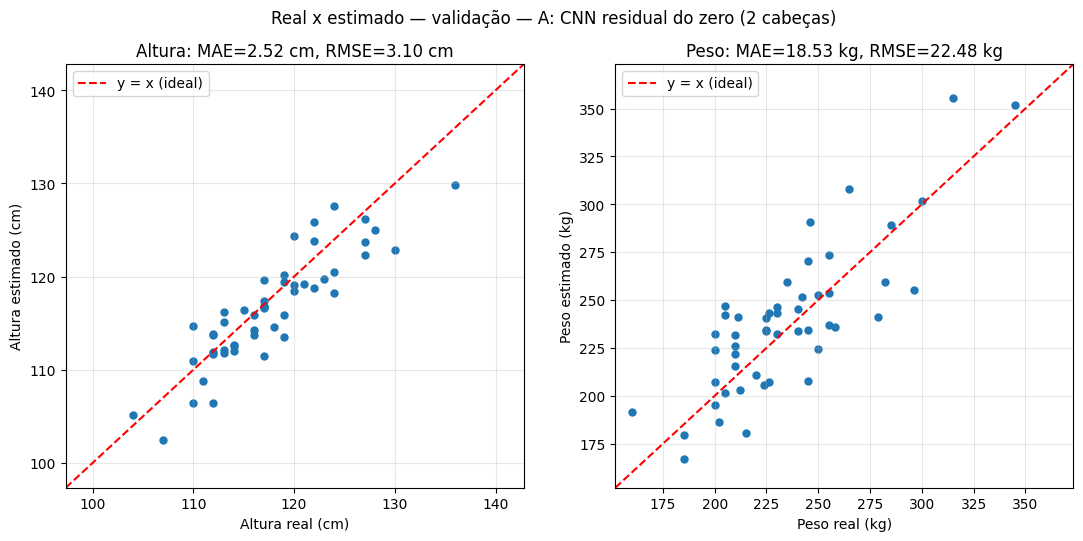

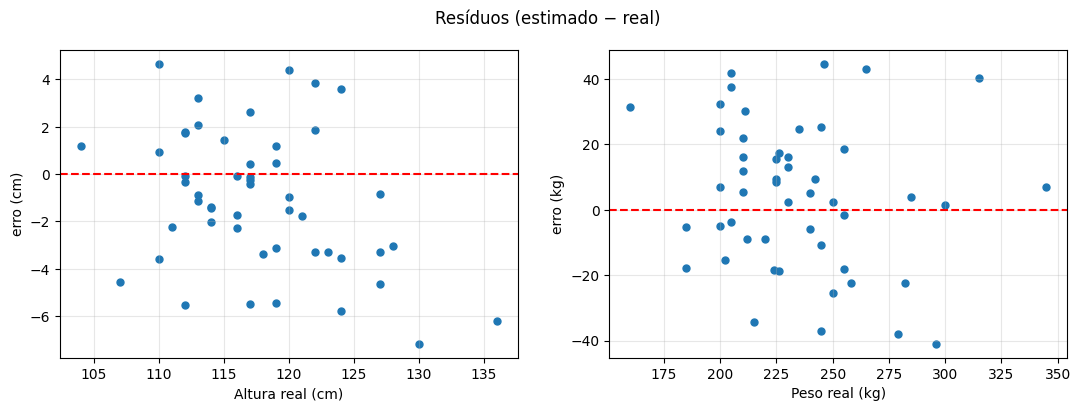

In [15]:
P = p_carr
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for j, (nome, un) in enumerate([('Altura', 'cm'), ('Peso', 'kg')]):
    lim = [min(Yva[:, j].min(), P[:, j].min()) * 0.95, max(Yva[:, j].max(), P[:, j].max()) * 1.05]
    ax[j].scatter(Yva[:, j], P[:, j], s=25)
    ax[j].plot(lim, lim, 'r--', label='y = x (ideal)')
    ax[j].set_xlim(lim); ax[j].set_ylim(lim)
    ax[j].set_xlabel(f'{nome} real ({un})'); ax[j].set_ylabel(f'{nome} estimado ({un})')
    m = metricas(Yva, P)
    ax[j].set_title(f'{nome}: MAE={m[f"MAE {nome.lower()} ({un})"]:.2f} {un}, RMSE={m[f"RMSE {nome.lower()} ({un})"]:.2f} {un}')
    ax[j].legend(); ax[j].grid(alpha=.3)
plt.suptitle(f'Real x estimado — validação — {nome_melhor}'); plt.show()

# Erro em função do valor real: o modelo erra mais nos extremos?
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for j, (nome, un) in enumerate([('Altura', 'cm'), ('Peso', 'kg')]):
    ax[j].scatter(Yva[:, j], P[:, j] - Yva[:, j], s=25); ax[j].axhline(0, c='r', ls='--')
    ax[j].set_xlabel(f'{nome} real ({un})'); ax[j].set_ylabel(f'erro ({un})'); ax[j].grid(alpha=.3)
plt.suptitle('Resíduos (estimado − real)'); plt.show()

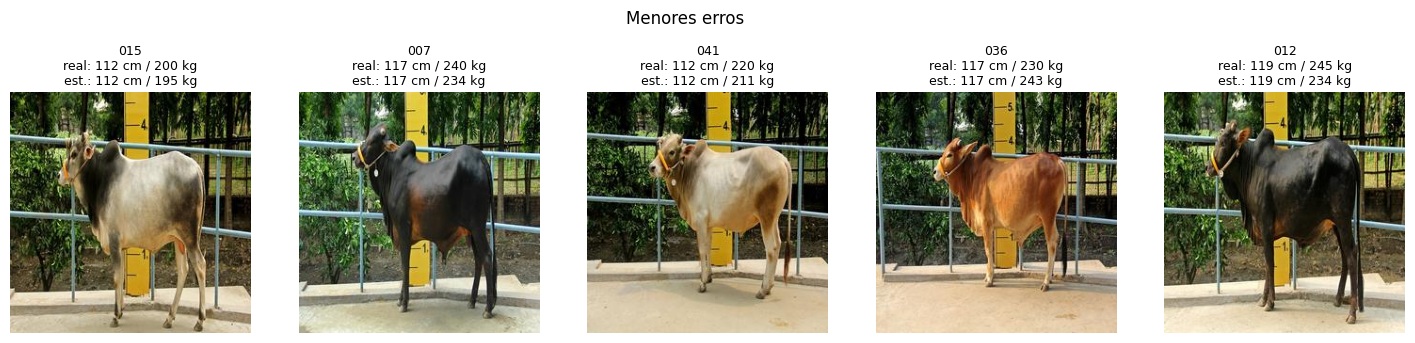

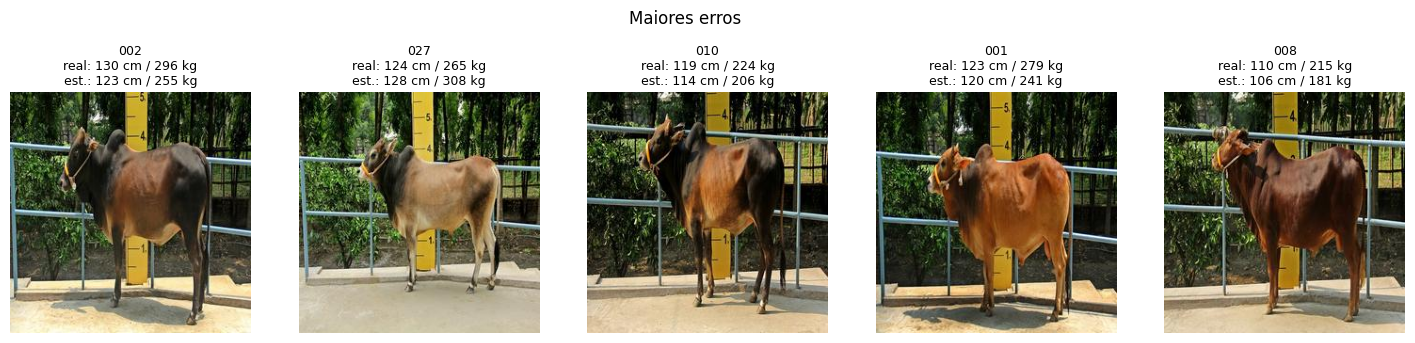

In [16]:
# Exemplos com menor e maior erro (erro relativo ao desvio padrão, altura + peso)
erro = (np.abs(P - Yva) / SD).sum(1)
ordem = np.argsort(erro)
for titulo, idx in [('Menores erros', ordem[:5]), ('Maiores erros', ordem[-5:][::-1])]:
    fig, ax = plt.subplots(1, 5, figsize=(18, 4.2))
    for a, k in zip(ax, idx):
        a.imshow(Xva[k]); a.axis('off')
        a.set_title(f'{ids_va[k]}\nreal: {Yva[k,0]:.0f} cm / {Yva[k,1]:.0f} kg\nest.: {P[k,0]:.0f} cm / {P[k,1]:.0f} kg', fontsize=9)
    plt.suptitle(titulo); plt.show()

### Discussão

**Resumo (validação, 50 imagens)**

| Modelo | MAE altura (cm) | RMSE altura (cm) | MAE peso (kg) | RMSE peso (kg) | MAPE peso | Parâmetros |
|---|---|---|---|---|---|---|
| Baseline (média do treino) | 5,06 | 6,28 | 36,10 | 42,40 | 16,5 % | – |
| **A: CNN residual do zero (2 cabeças)** | **2,52** | **3,10** | **18,53** | **22,48** | **8,0 %** | 1,30M |
| B: EfficientNetB0 + 2 cabeças | 2,62 | 3,35 | 20,20 | 24,42 | 8,9 % | 4,38M |
| C: EfficientNetB0 + 1 cabeça | 2,62 | 3,35 | 20,51 | 24,79 | 9,0 % | 4,21M |

O melhor modelo (A) foi salvo em `melhor_modelo.keras`. Depois de recarregado, ele produz exatamente as mesmas previsões (diferença máxima de 0,0), e todos os modelos respeitam o limite de 5M parâmetros.

**Significado dos erros.** Todos os modelos reduzem aproximadamente pela metade o erro do baseline que sempre prevê a média.
- **Altura:** o modelo A erra em média **2,5 cm**, cerca de 2 % da altura média (118,5 cm) e ≈0,3 desvio padrão.
- **Peso:** o erro médio é de **18,5 kg**, cerca de **8 %** do peso médio (256 kg).

Em termos relativos, o peso é estimado com um erro cerca de 4 vezes maior que a altura. Isso é coerente com a natureza das duas grandezas: a altura é uma medida linear diretamente visível na foto de perfil, inclusive com a régua graduada ao fundo como referência de escala. Já o peso depende do **volume** e da densidade corporal, que uma única vista 2D captura apenas parcialmente (largura do tronco, profundidade e condição corporal não aparecem por completo). Para aplicações de manejo, um erro de ~8 % no peso é útil como estimativa rápida e sem contato, mas não substitui a balança em decisões que exigem precisão (por exemplo, dosagem de medicamentos).

**Padrões de erro.** Os gráficos de real × estimado e de resíduos mostram **regressão à média**: o modelo subestima animais grandes (ex.: 136 cm → 130 cm; 296 kg → 255 kg) e superestima animais leves (ex.: 160 kg → 191 kg), com resíduos de peso que decrescem conforme o peso real aumenta. Isso é esperado porque os extremos têm poucas amostras no treino e a perda penaliza mais os erros na região de maior densidade de dados. Vale notar que a validação só contém animais entre 160 e 345 kg, enquanto o treino chega a 816 kg: o comportamento do modelo em animais muito pesados não foi medido, e o erro tende a ser maior nesses casos. Entre os maiores erros (imagens 002, 027 e 001) aparecem animais com o corpo levemente rotacionado em relação à câmera ou com pelagem e iluminação diferentes da maioria. Variações de pose alteram a área visível do animal e prejudicam sobretudo a estimativa de peso.

**Overfitting.** Nenhum modelo apresenta sobreajuste relevante.
- **A:** a perda de validação oscila bastante nas primeiras épocas, o que é típico de BatchNorm treinada do zero com lotes pequenos (16), mas converge junto com a de treino, sem gap crescente. O early stopping interrompeu o treino na época 137.
- **B/C:** a perda de validação fica no nível da de treino ou abaixo dela, efeito do dropout e do aumento de dados, que só atuam no treino. O início do fine-tuning (linha tracejada) produz uma queda clara das duas perdas.

**Comparação dos experimentos.**
- **Do zero (A) × transfer learning (B):** a CNN residual do zero obteve as menores métricas com 3,4× menos parâmetros que a EfficientNetB0. Uma explicação plausível é que o domínio é muito padronizado (mesmo cenário, mesma pose e régua fixa), de modo que características genéricas do ImageNet trazem pouca vantagem sobre uma rede menor treinada especificamente para o problema.
- **Duas cabeças (B) × uma cabeça (C):** os resultados são praticamente idênticos, o que indica que a representação convolucional compartilhada é o que importa e que separar as cabeças traz, no máximo, um ganho marginal no peso.
- **KerasTuner:** a melhor configuração encontrada foi lr = 1e-3, dropout = 0,3, sem L2, 128 unidades e perda Huber, confirmando a escolha inicial da Huber.

**Limitações.** A validação tem apenas 50 imagens, então diferenças da ordem de 0,1 cm ou 1–2 kg entre os modelos provavelmente não são estatisticamente significativas. Além disso, o mesmo conjunto de validação foi usado no early stopping, na busca de hiperparâmetros e na seleção do modelo final, o que torna as métricas reportadas levemente otimistas. É esperado um erro um pouco maior no conjunto de teste secreto. Possíveis melhorias incluem um *ensemble* de A e B, *test-time augmentation* (média das previsões da imagem original e espelhada) e um fine-tuning mais profundo da EfficientNet, já que ela não mostrou sinais de sobreajuste.


## 9. Predição no conjunto de teste

A função abaixo baixa um `.zip` com o mesmo formato do dataset divulgado, gera as estimativas para **todas as imagens do diretório `images`** e salva um `.csv` no mesmo formato de `annotations.csv` (sem cabeçalho): `id,altura,peso`.

Para demonstrar, ela é executada com o link do próprio dataset de treino. **Na avaliação, basta trocar `URL_TESTE` pelo hyperlink do conjunto de teste.**

In [17]:
URL_TESTE = 'https://raw.githubusercontent.com/tltsilveira/ufsm00993/main/dataset_8.zip'  # <- trocar pelo link de teste

def gerar_predicoes(url, modelo, pasta='teste', saida='predicoes.csv'):
    os.makedirs(pasta, exist_ok=True)
    arq = os.path.join(pasta, 'teste.zip')
    urllib.request.urlretrieve(url, arq)
    with zipfile.ZipFile(arq) as z:
        z.extractall(pasta)
    dir_img = os.path.join(pasta, 'images')
    nomes = sorted(n for n in os.listdir(dir_img)
                   if n.lower().endswith(('.jpg', '.jpeg', '.png')) and not n.startswith('.'))
    Xt = np.stack([ler_imagem(os.path.join(dir_img, n)) for n in nomes]).astype('float32') / 255.0
    Pt = prever(modelo, Xt)
    with open(saida, 'w', newline='') as f:
        w = csv.writer(f)
        for n, (a, p) in zip(nomes, Pt):
            w.writerow([os.path.splitext(n)[0], f'{a:.2f}', f'{p:.2f}'])
    print(f'{len(nomes)} imagens -> {saida}')
    return nomes, Pt

modelo_final = keras.models.load_model('melhor_modelo.keras')
nomes_t, Pt = gerar_predicoes(URL_TESTE, modelo_final)
print(open('predicoes.csv').read()[:300])

514 imagens -> predicoes.csv
001,119.70,241.15
002,122.83,255.04
003,113.74,202.95
004,110.93,186.52
005,112.63,201.20
006,118.73,235.71
007,116.76,234.01
008,106.40,180.64
009,112.59,207.19
010,113.57,205.68
011,113.71,207.89
012,119.47,234.36
013,125.87,273.43
014,102.46,167.25
015,111.94,194.98
016,106.48,179.67
017,111.51,2


## 10. Roteiro para o pitch (05/11)
1. **Problema:** estimar altura e peso de bovinos a partir de uma foto (513 imagens anotadas).
2. **Dados:** fotos de perfil com régua ao fundo; peso assimétrico; correlação de 0,77 entre altura e peso; alvos padronizados.
3. **Arquitetura:** diagrama EfficientNetB0 (congelada → fine-tuning) + GAP + duas cabeças; nº de parâmetros (< 5M).
4. **Decisões de treino:** perda Huber, Adam + ReduceLROnPlateau, early stopping, aumento de dados que preserva a escala, KerasTuner.
5. **Resultados:** tabela A/B/C contra o baseline (MAE/RMSE de altura e peso) e gráficos real × estimado.
6. **Exemplos:** imagens com as estimativas (acertos e erros) e lições aprendidas.